# MwC 04 — nTRD versus TRD analysis

Test the selected MwC deviations using the formal 26-ROI age/sex-adjusted data.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `mwc`; step 4 of 5
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


,input,size_kib
0,03_compute_normative_sc_mwc.py,12.4
1,session_gcmi_pet_AAL3_144.npz,17230.9
2,normative_SC_top10_mask.npz,53.7
3,subject_level_corticolimbic26_normativeSC10_Mw...,122.4
4,subject_level_AAL3_144_normativeSC10_MwC_wide....,292.3
5,validation_report.json,0.2
6,corticolimbic_12x14_ROI_definition.csv,0.6
7,clinical_data.xlsx,11.0
8,subject_level_corticolimbic26_age_sex_adjusted...,136.2


{
  "full_144": "./outputs/mwc/recomputed_normative_sc/subject_level_AAL3_144_normativeSC10_MwC_wide.csv.gz",
  "selected_26": "./outputs/mwc/recomputed_normative_sc/subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
  "validation": "./outputs/mwc/recomputed_normative_sc/calculation_validation_report.json"
}
PASS: AAL3-144 normative-SC-constrained MwC recomputed before 26-ROI extraction


,check,passed
0,sessions_255,True
1,retained_AAL3_nodes_144,True
2,fixed_dTOR_normative_SC_edges_1030,True
3,gcmi_floor_bits_0p01,True
4,row_normalization_error_below_1e_12,True
5,all_144_nodes_computed_before_26_extraction,True
6,isolated_nodes_remain_missing,True
7,full_144_matches_validated_reference,True
8,selected_26_matches_validated_reference,True


,quantity,value
0,upstream paired sessions,255.0
1,clinical sessions,255.0
2,ROIs per session,26.0
3,long-table rows,6630.0
4,all-144 to 26 extraction maximum absolute error,0.0


,node_index,network,AAL3_ID,ROI
0,1,cortical,3,Frontal_Sup_2_L
1,2,cortical,4,Frontal_Sup_2_R
2,3,cortical,5,Frontal_Mid_2_L
3,4,cortical,6,Frontal_Mid_2_R
4,5,cortical,19,Frontal_Sup_Medial_L
5,6,cortical,20,Frontal_Sup_Medial_R
6,7,cortical,21,Frontal_Med_Orb_L
7,8,cortical,22,Frontal_Med_Orb_R
8,9,cortical,25,OFCmed_L
9,10,cortical,26,OFCmed_R


,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,86,0.956093,0.0,0.884615,0.822359,HC-only age/sex residual z scores; 26 ROIs ext...


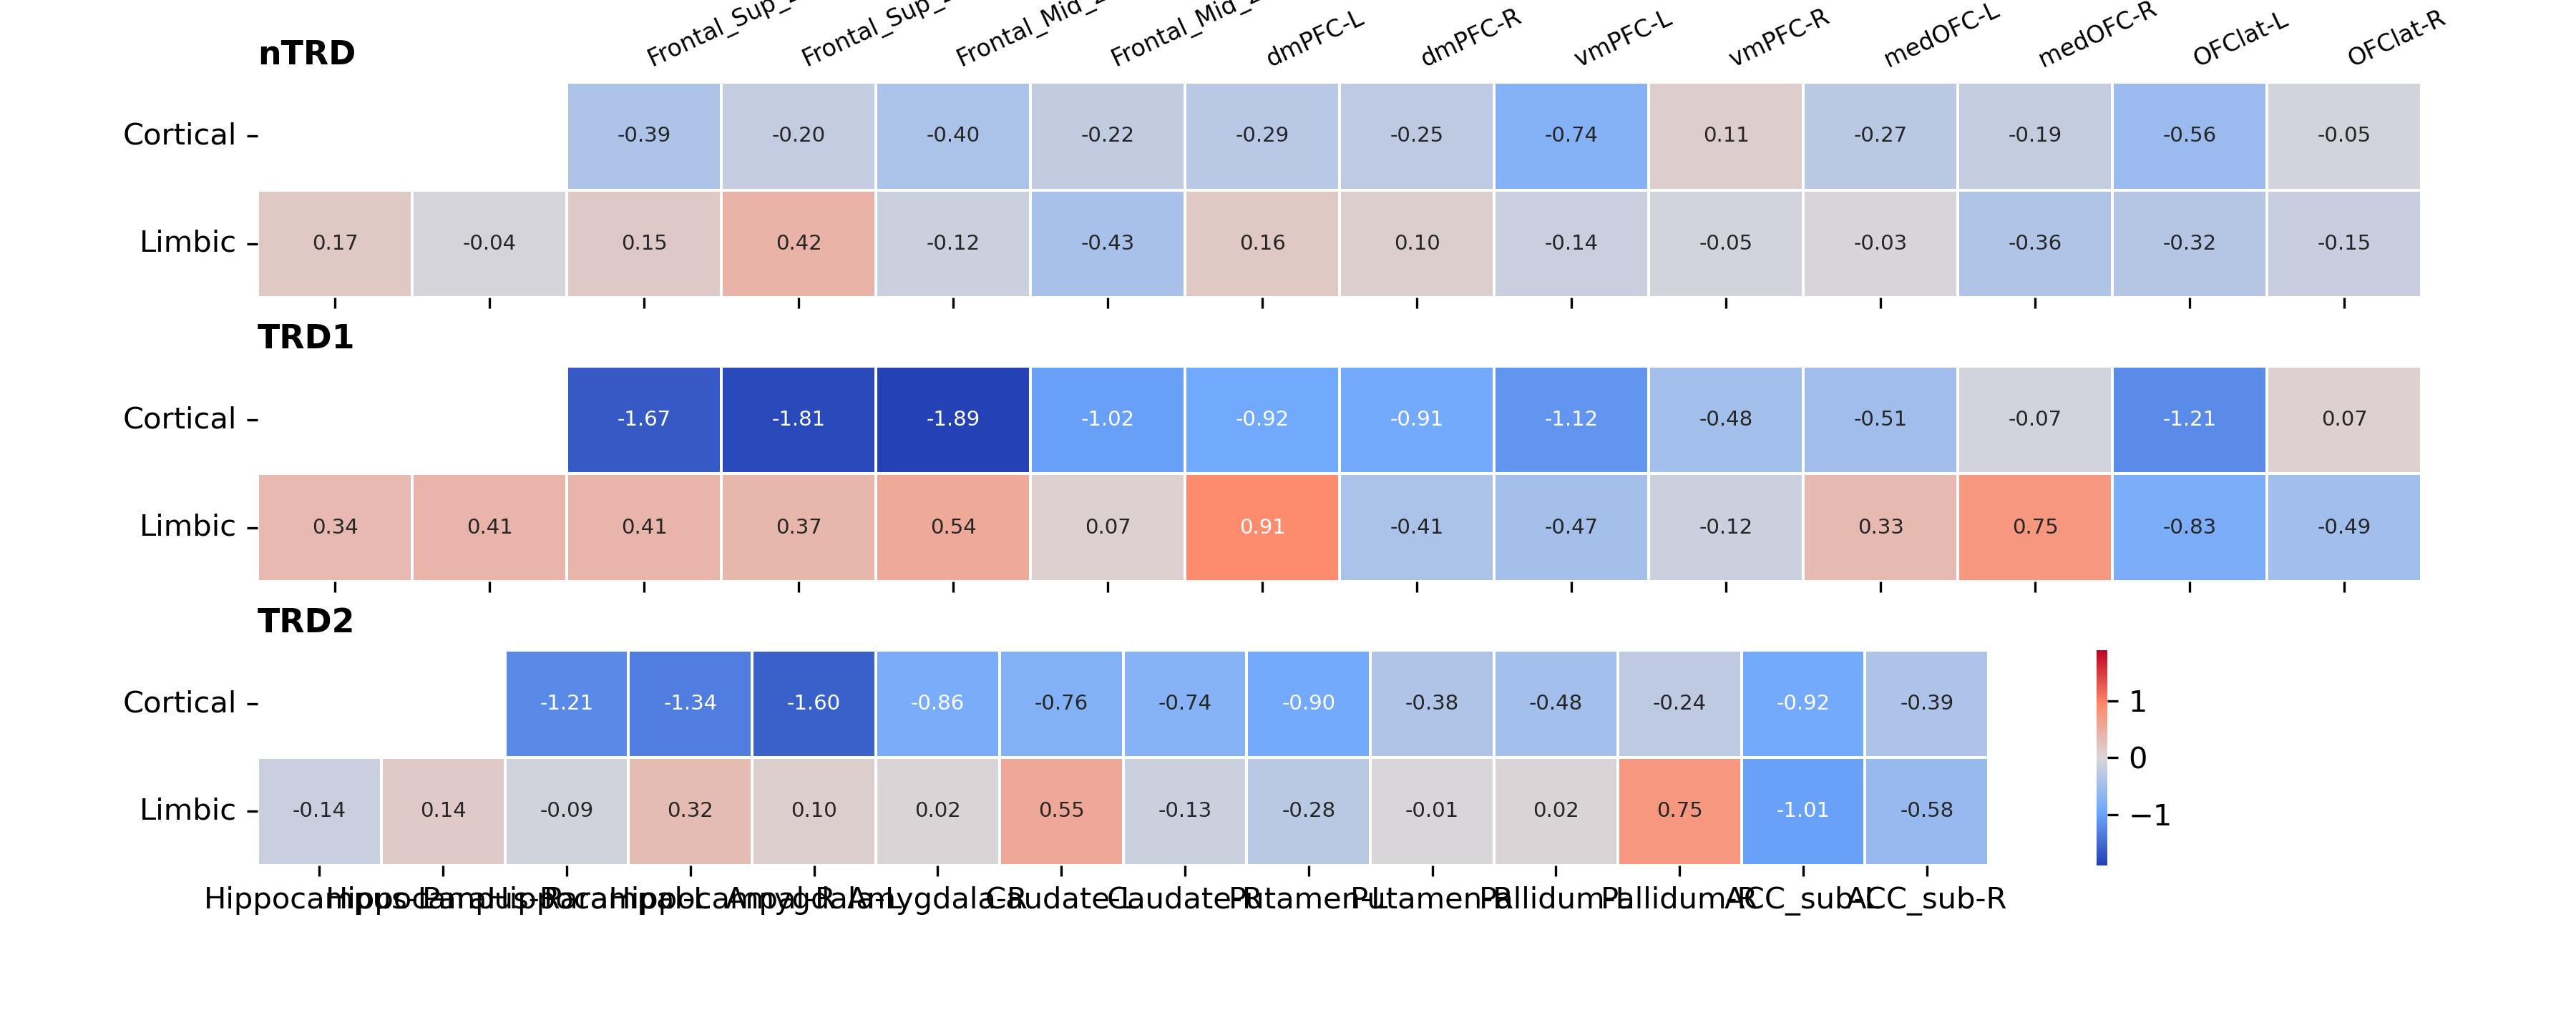

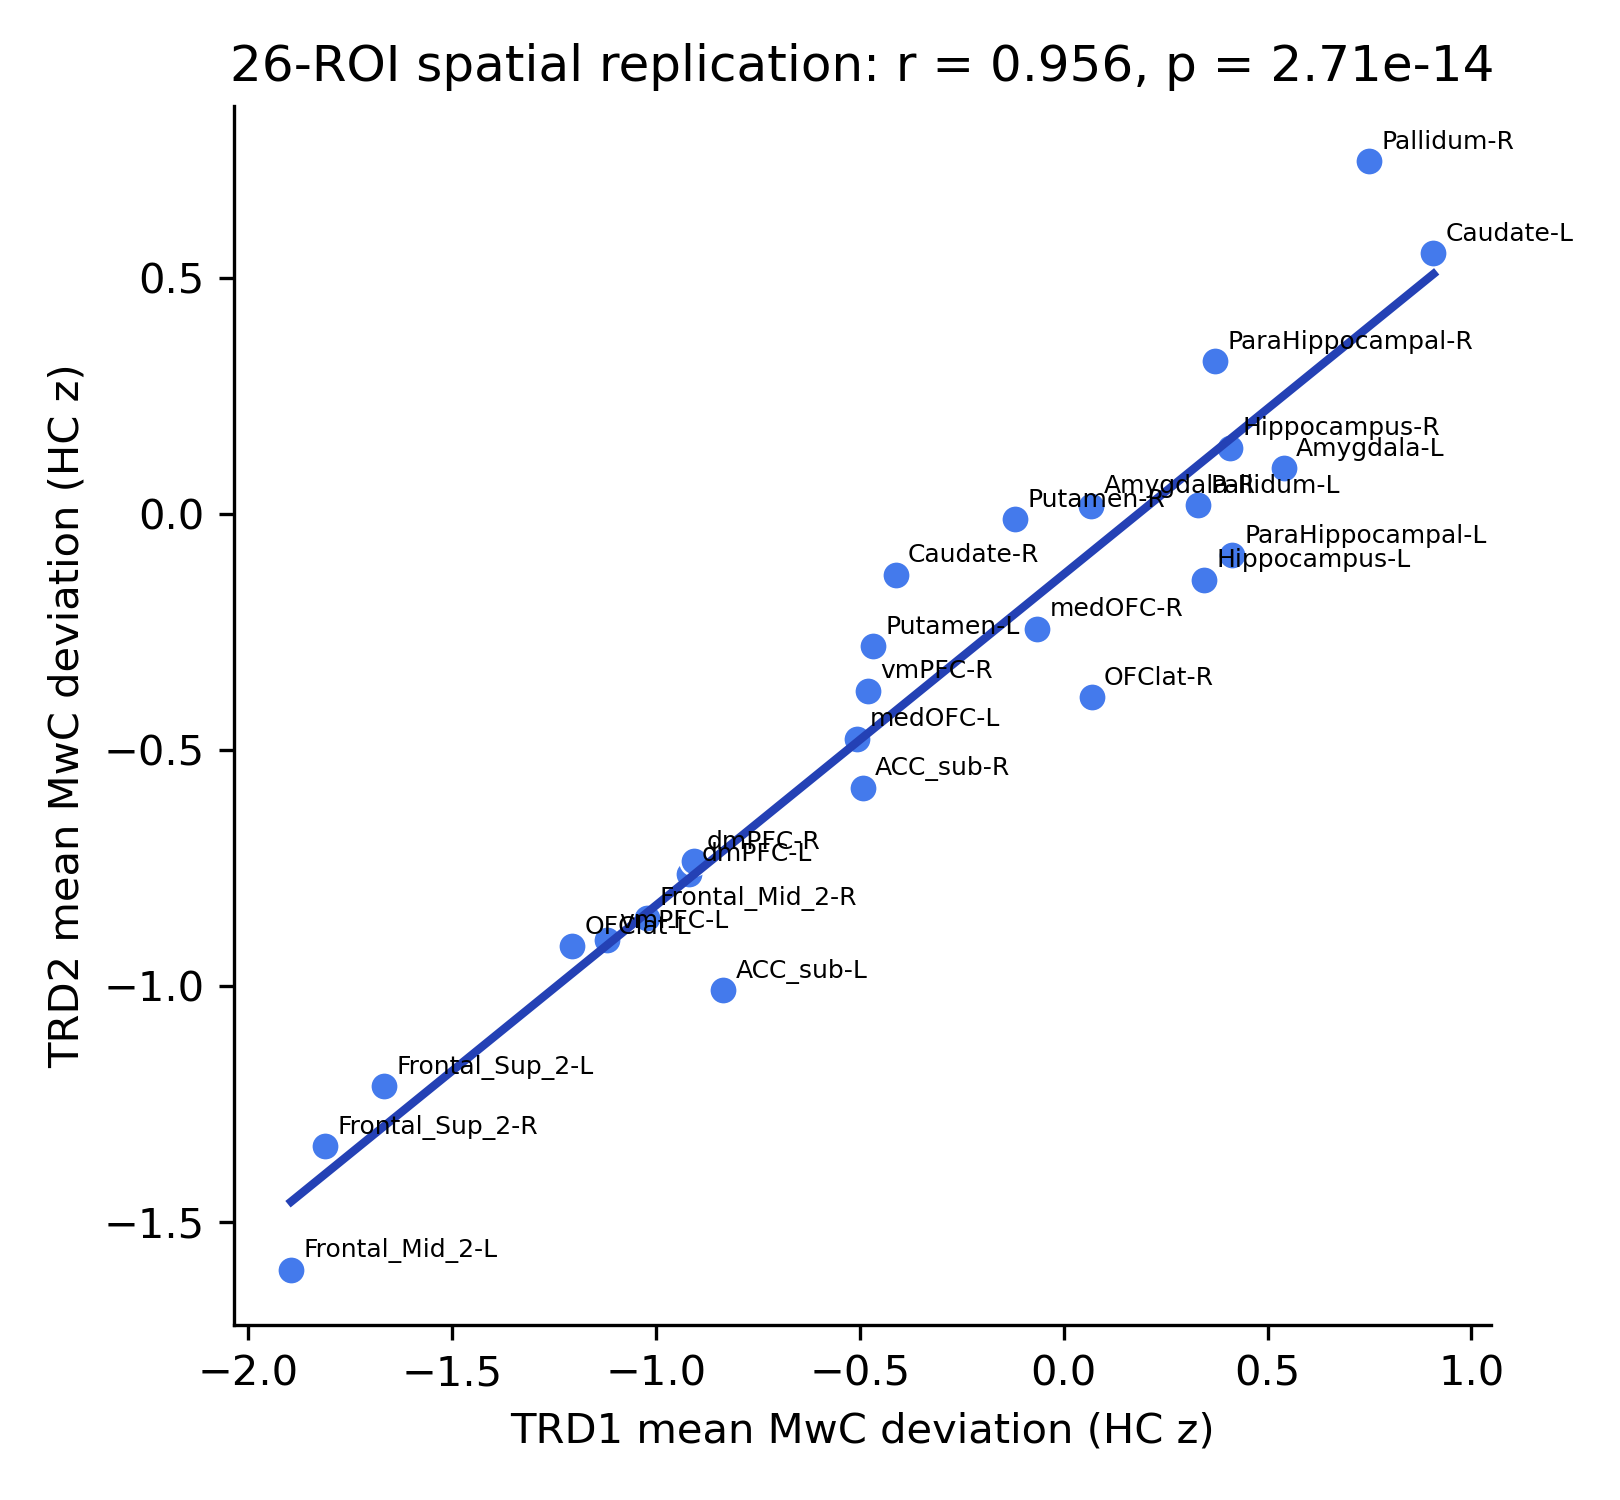

In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("mwc_01_setup_recompute.py")
_run_step("mwc_02_subject_level.py")
_run_step("mwc_03_deviation_spatial.py")


## Preamble


In [2]:
"""Auto-extracted pipeline step: MwC 04 — final nTRD versus TRD analysis.

Do not edit generated copies independently of the source notebooks.
"""


'Auto-extracted pipeline step: MwC 04 — final nTRD versus TRD analysis.\n\nDo not edit generated copies independently of the source notebooks.\n'

## Source 12


In [3]:
SELECTED_ROIS = {
    "SFG_L": "MwC_deviation_Frontal_Sup_2_L",
    "MFG_L": "MwC_deviation_Frontal_Mid_2_L",
    "vmPFC_R": "MwC_deviation_Frontal_Med_Orb_R",
    "PAL_L": "MwC_deviation_Pallidum_L",
    "HPC_R": "MwC_deviation_Hippocampus_R",
    "AMY_R": "MwC_deviation_Amygdala_R",
}

baseline = mwc_adjusted_26.loc[
    mwc_adjusted_26.session.eq("ses-01")
    & mwc_adjusted_26.analysis_cohort.isin(["nTRD", "TRD1"])
].copy()
assert baseline.groupby("analysis_cohort").size().to_dict() == {"TRD1": 35, "nTRD": 25}
for deviation_metric in SELECTED_ROIS.values():
    source_metric = deviation_metric.replace("MwC_deviation_", "MwC_", 1)
    baseline[deviation_metric] = baseline[source_metric].to_numpy(float)


def adjusted_group_test(frame: pd.DataFrame, region: str, metric: str) -> dict[str, object]:
    data = frame[[metric, "analysis_cohort", "age", "sex"]].dropna().copy()
    data["trd"] = data.analysis_cohort.eq("TRD1").astype(float)
    data["age_c"] = data.age - data.age.mean()
    design = sm.add_constant(data[["trd", "age_c", "sex"]], has_constant="add")
    model = sm.OLS(data[metric], design).fit(cov_type="HC3")
    ci = model.conf_int().loc["trd"].to_numpy(float)
    ntrd = data.loc[data.analysis_cohort.eq("nTRD"), metric].to_numpy(float)
    trd = data.loc[data.analysis_cohort.eq("TRD1"), metric].to_numpy(float)
    return {
        "region": region,
        "metric": metric,
        "comparison": "TRD - nTRD",
        "covariates": "age + sex",
        "n_nTRD": len(ntrd),
        "n_TRD": len(trd),
        "nTRD_mean_HC_z": float(np.mean(ntrd)),
        "nTRD_sd_HC_z": float(np.std(ntrd, ddof=1)),
        "TRD_mean_HC_z": float(np.mean(trd)),
        "TRD_sd_HC_z": float(np.std(trd, ddof=1)),
        "beta_TRD_minus_nTRD_HC_SD": float(model.params["trd"]),
        "hc3_se": float(model.bse["trd"]),
        "ci95_low_TRD_minus_nTRD_HC_SD": float(ci[0]),
        "ci95_high_TRD_minus_nTRD_HC_SD": float(ci[1]),
        "p_adjusted": float(model.pvalues["trd"]),
    }


adjusted_statistics = pd.DataFrame(
    [adjusted_group_test(baseline, region, metric) for region, metric in SELECTED_ROIS.items()]
)
adjusted_statistics.to_csv(
    OUTPUT_DIR / "ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv",
    index=False,
)

assert len(adjusted_statistics) == len(SELECTED_ROIS) == 6
assert adjusted_statistics[["p_adjusted", "beta_TRD_minus_nTRD_HC_SD"]].notna().all().all()
expected_complete_cases = {}
for region, metric in SELECTED_ROIS.items():
    complete = baseline[[metric, "analysis_cohort", "age", "sex"]].dropna()
    counts = complete.groupby("analysis_cohort").size().to_dict()
    expected_complete_cases[region] = {
        "n_nTRD": int(counts.get("nTRD", 0)),
        "n_TRD": int(counts.get("TRD1", 0)),
    }

observed_complete_cases = adjusted_statistics.set_index("region")[["n_nTRD", "n_TRD"]].astype(int)
for region, counts in expected_complete_cases.items():
    assert observed_complete_cases.loc[region].to_dict() == counts
assert (observed_complete_cases >= 20).all().all()

display(adjusted_statistics.round(6))


,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.392507,1.208856,-1.666740,2.002653,-1.275234,0.395321,-2.050048,-0.500419,0.001256
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.403144,1.679665,-1.893879,1.886119,-1.511057,0.423559,-2.341218,-0.680896,0.000360
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.114952,1.469150,-0.479734,1.127049,-0.692292,0.375222,-1.427714,0.043130,0.065035
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.027443,1.151591,0.330573,1.142455,0.497369,0.282615,-0.056546,1.051283,0.078428
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.043946,0.928577,0.409091,1.022139,0.583273,0.248516,0.096191,1.070354,0.018924
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.430192,0.982046,0.067972,0.769642,0.465657,0.217533,0.039300,0.892014,0.032304


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


In [4]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'Adjusted nTRD-versus-TRD MwC statistics', 'path': 'outputs/mwc/ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv'}]
_inline_figure_paths = []

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))


### Key tables

**Adjusted nTRD-versus-TRD MwC statistics**  
`outputs/mwc/ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv` — 6 rows × 15 columns

,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.392507,1.208856,-1.666740,2.002653,-1.275234,0.395321,-2.050048,-0.500419,0.001256
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.403144,1.679665,-1.893879,1.886119,-1.511057,0.423559,-2.341218,-0.680896,0.000360
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.114952,1.469150,-0.479734,1.127049,-0.692292,0.375222,-1.427714,0.043130,0.065035
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.027443,1.151591,0.330573,1.142455,0.497369,0.282615,-0.056546,1.051283,0.078428
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.043946,0.928577,0.409091,1.022139,0.583273,0.248516,0.096191,1.070354,0.018924
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.430192,0.982046,0.067972,0.769642,0.465657,0.217533,0.039300,0.892014,0.032304
